In [76]:
import pandas
from astropy.io.votable import parse
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

In [ ]:
# Pre-release file

votable = parse("prerelease_DR4_test/GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml")
table = votable.get_first_table().to_table()

In [78]:
# Choosing the BH3 source since its a nice example
source_id = 4318465066420528000 # BH3
# source = table[table["source_id"] == source_id]
# From astropy type to pandas data frame
df = table.to_pandas()
source = df[df["source_id"] == source_id]
# Note on data shape.
# For this source there are:
# 77 transits
# for each transit (fet) there are 10 CCD's 
# fet 1 ra0, 1 dec0
# fet 10 scan_pos_angle, centroid_pos_error_al, used_by_agis etc.

In [ ]:
def numeric_array(series):
    return np.asarray(
        [
            [
                np.nan if value is None or str(value) == "--" else float(value)
                for value in row
            ]
            for row in series
        ],
        dtype=float,
    )

In [ ]:


def al_scan_direction(scan_pos_angle):
    """
    Return the unit vector along the Gaia along-scan direction.

    Parameters
    ----------
    scan_pos_angle : array-like
        Scan position angle in degrees.

    Returns
    -------
    ux, uy : ndarray
        Components of the AL unit vector in the sky plane:

        ux = sin(theta)
        uy = cos(theta)
    """
    theta = np.deg2rad(scan_pos_angle, dtype=float)

    return np.sin(theta), np.cos(theta)

def offset_pos(scan_pos_angle, centroid_al, centroid_ac):
    """Convert AL/AC centroid offsets to RA/Dec-plane offsets."""

    scan_pos_angle = np.asarray(scan_pos_angle, dtype=float)
    centroid_al = np.asarray(centroid_al, dtype=float)
    centroid_ac = np.asarray(centroid_ac, dtype=float)

    if scan_pos_angle.ndim != 2:
        print("ERROR")
        raise ValueError("scan_pos_angle must be a 2D array.")

    if centroid_al.shape != scan_pos_angle.shape:
        print("ERROR")
        raise ValueError("centroid_al must have the same shape as scan_pos_angle.")

    if centroid_ac.shape != scan_pos_angle.shape:
        print("ERROR")
        raise ValueError("centroid_ac must have the same shape as scan_pos_angle.")

    s, c = al_scan_direction(scan_pos_angle)

    ra_offsets = centroid_al * s - centroid_ac * c
    dec_offsets = centroid_al * c + centroid_ac * s
    return ra_offsets, dec_offsets


def error_lines(
    scan_pos_angle,
    ra_offsets,
    dec_offsets,
    al_error,
    ac_error,
):
    """
    Build AL and AC uncertainty segments for sky-plane points.

    The AL uncertainty is drawn parallel to the scan direction.

    The AC uncertainty is drawn perpendicular to the scan direction.

    All offsets and errors must use the same units, normally mas.

    Returns
    -------
    al_segments : ndarray
        Array with shape (N, 2, 2), suitable for LineCollection.

    ac_segments : ndarray
        Array with shape (N, 2, 2), suitable for LineCollection.
    """
    scan_pos_angle = np.asarray(scan_pos_angle, dtype=float)
    ra_offsets = np.asarray(ra_offsets, dtype=float)
    dec_offsets = np.asarray(dec_offsets, dtype=float)
    al_error = np.asarray(al_error, dtype=float)
    ac_error = np.asarray(ac_error, dtype=float)

    # Along-scan unit vector.
    ux, uy = al_scan_direction(scan_pos_angle)

    # Across-scan unit vector, perpendicular to the AL direction.
    px = -uy
    py = ux

    # Coordinates of the central sky-plane positions.
    points = np.column_stack((ra_offsets, dec_offsets))

    # AL uncertainty endpoints:
    #
    # p_AL,- = p - sigma_AL * u_AL
    # p_AL,+ = p + sigma_AL * u_AL
    al_start = points - al_error[:, None] * np.column_stack((ux, uy))
    al_end = points + al_error[:, None] * np.column_stack((ux, uy))

    # AC uncertainty endpoints:
    #
    # p_AC,- = p - sigma_AC * u_AC
    # p_AC,+ = p + sigma_AC * u_AC
    ac_start = points - ac_error[:, None] * np.column_stack((px, py))
    ac_end = points + ac_error[:, None] * np.column_stack((px, py))

    # LineCollection expects:
    #
    # segments[i] = [[x_start, y_start], [x_end, y_end]]
    al_segments = np.stack((al_start, al_end), axis=1)
    ac_segments = np.stack((ac_start, ac_end), axis=1)

    return al_segments, ac_segments

(77, 10) (77, 10)
(77, 10) (77, 10)


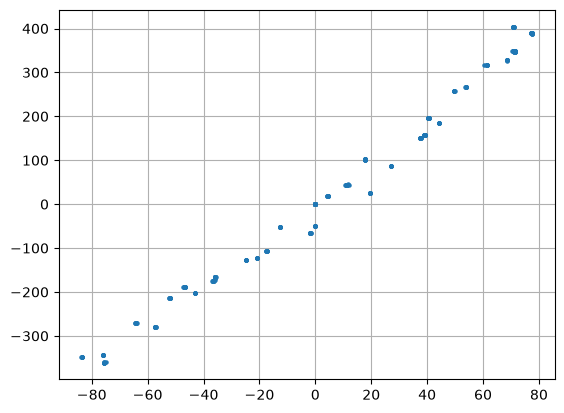

In [ ]:
scan = numeric_array(source['scan_pos_angle'])
centroid_al = numeric_array(source['centroid_pos_al'])
centroid_ac = numeric_array(source['calculated_pos_ac'])
reject = numeric_array(source['used_by_agis_al'])

d_ra, d_dec = offset_pos(scan, centroid_al, centroid_ac)
plt.scatter(d_ra * reject, d_dec  * reject, s = 5, alpha = 1, zorder =3)
plt.autoscale()
plt.grid()

# plotting errors is a little bit of a pain, so left it until requested